1. Генерация датасета

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Фиксируем seed для воспроизводимости
np.random.seed(42)
n_samples = 1000

# a. X1 - равномерно от 0 до 10
X1 = np.random.uniform(0, 10, n_samples)
# b. X2 - равномерно от 0 до 10
X2 = np.random.uniform(0, 10, n_samples)
# c. X3 = X1 + X2 + eps, eps ~ N(0, 5)
eps3 = np.random.normal(0, np.sqrt(5), n_samples)
X3 = X1 + X2 + eps3
# d. X4 - нормально со средним 10 и дисперсией 9
X4 = np.random.normal(10, np.sqrt(9), n_samples)
# e. X5 = 2*X4 + eps, eps ~ N(1, 3)
eps5 = np.random.normal(1, np.sqrt(3), n_samples)
X5 = 2 * X4 + eps5
# f. X6 - экспоненциально с lambda = 0.5
# numpy.random.exponential принимает scale = 1/lambda
X6 = np.random.exponential(1/0.5, n_samples)
# g. X7 = sqrt(X6)
X7 = np.sqrt(X6)
# h. X8 - бинарная (0 или 1) равномерно
X8 = np.random.randint(0, 2, n_samples)

# Создаем DataFrame
df = pd.DataFrame({
    'X1': X1, 'X2': X2, 'X3': X3, 'X4': X4,
    'X5': X5, 'X6': X6, 'X7': X7, 'X8': X8
})

print("Первые 5 строк датасета:")
print(df.head())

Первые 5 строк датасета:
         X1        X2         X3         X4         X5        X6        X7  X8
0  3.745401  1.851329   3.633502  15.612896  32.826310  0.594529  0.771057   1
1  9.507143  5.419009  13.077192  11.168843  27.687829  2.541566  1.594229   1
2  7.319939  8.729458  15.542976   7.395122  12.603135  0.057049  0.238849   1
3  5.986585  7.322249  14.130288  11.603887  24.151863  0.941036  0.970070   1
4  1.560186  8.065611  11.668635   2.092757   6.294966  1.971032  1.403934   1


2. Коэффициент корреляции

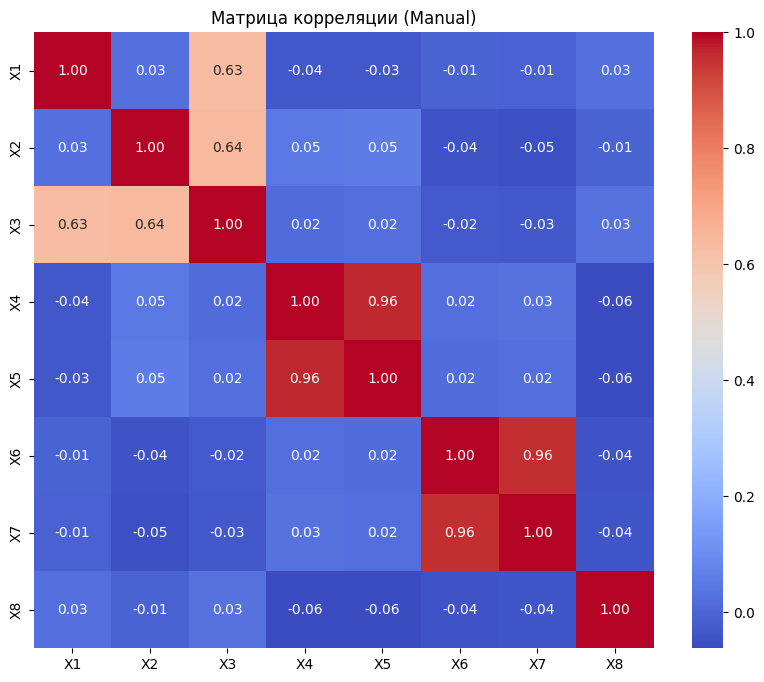

In [2]:
def manual_correlation_matrix(data):
    """
    Ручной расчет матрицы корреляции Пирсона.
    Формула: r = sum((x - mean_x) * (y - mean_y)) / sqrt(sum((x - mean_x)^2) * sum((y - mean_y)^2))
    """
    n = data.shape[1]
    corr_matrix = np.zeros((n, n))
    
    # Стандартизация данных (центрирование и нормировка)
    # Это упрощает формулу: r = (1/n) * sum(x_norm * y_norm)
    means = np.mean(data, axis=0)
    stds = np.std(data, axis=0)
    
    # Избегаем деления на ноль, если std = 0
    stds[stds == 0] = 1 
    
    normalized_data = (data - means) / stds
    
    for i in range(n):
        for j in range(n):
            # Скалярное произведение нормализованных векторов / n
            corr_matrix[i, j] = np.dot(normalized_data[:, i], normalized_data[:, j]) / data.shape[0]
            
    return corr_matrix

# Расчет
corr_mat = manual_correlation_matrix(df.values)

# Визуализация
plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", xticklabels=df.columns, yticklabels=df.columns, cmap='coolwarm')
plt.title("Матрица корреляции (Manual)")
plt.show()

3. Реализация PCA на основе SVD

In [3]:
def manual_svd_pca(data, n_components=2):
    """
    Реализация PCA через SVD (фактически через Eigendecomposition ковариационной матрицы,
    что эквивалентно SVD для центрированных данных).
    Используем степенной метод для поиска собственных векторов.
    """
    # 1. Центрирование данных
    mean = np.mean(data, axis=0)
    centered_data = data - mean
    
    # 2. Ковариационная матрица (C = X^T * X / (n-1))
    # Размерность (features x features)
    n_samples = data.shape[0]
    cov_matrix = np.dot(centered_data.T, centered_data) / (n_samples - 1)
    
    # 3. Поиск собственных векторов и значений (Степенной метод)
    # Мы будем искать компоненты последовательно (дефляция)
    eig_vals = []
    eig_vecs = []
    
    temp_cov = cov_matrix.copy()
    
    for _ in range(n_components):
        # Инициализация случайного вектора
        vec = np.random.rand(temp_cov.shape[0])
        vec = vec / np.linalg.norm(vec) # Нормализация (разрешена базовая математика)
        
        # Итерации степенного метода
        for _ in range(1000):
            # Умножение матрицы на вектор
            vec_new = np.dot(temp_cov, vec)
            # Нормализация
            norm = np.sqrt(np.sum(vec_new**2))
            vec_new = vec_new / norm
            
            # Проверка сходимости
            if np.abs(np.dot(vec, vec_new)) > 0.999999:
                break
            vec = vec_new
            
        # Собственное значение (отношение Релея)
        eigenvalue = np.dot(vec.T, np.dot(temp_cov, vec))
        
        eig_vals.append(eigenvalue)
        eig_vecs.append(vec)
        
        # Дефляция: вычитаем вклад найденной компоненты
        # temp_cov = temp_cov - eigenvalue * vec * vec^T
        temp_cov = temp_cov - eigenvalue * np.outer(vec, vec)
        
    eig_vecs = np.array(eig_vecs).T # Транспонируем, чтобы столбцы были векторами
    eig_vals = np.array(eig_vals)
    
    # 4. Проекция данных
    # Projection = X_centered * V
    projection = np.dot(centered_data, eig_vecs)
    
    return projection, eig_vals, eig_vecs, mean

# Применяем
n_comp = 2
projection, eigenvalues, eigenvectors, data_mean = manual_svd_pca(df.values, n_components=n_comp)

print(f"Собственные значения (дисперсии компонент): {eigenvalues}")

Собственные значения (дисперсии компонент): [49.93767489 29.55415467]


4. Проекция на 2D

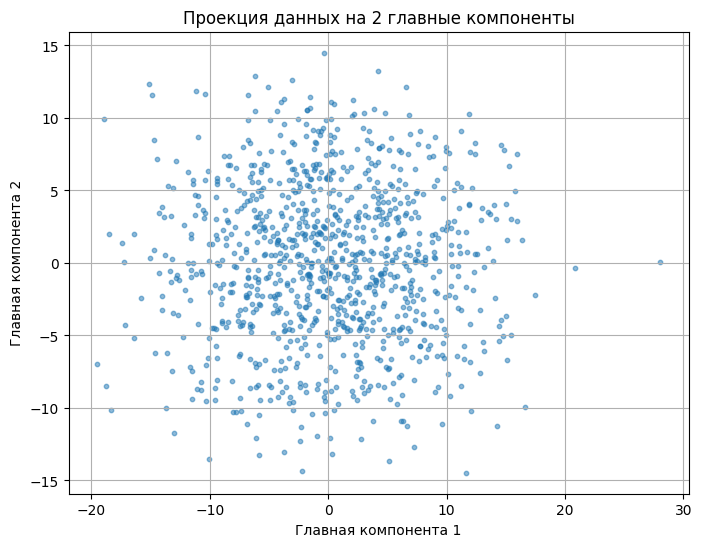

In [5]:
plt.figure(figsize=(8, 6))
plt.scatter(projection[:, 0], projection[:, 1], alpha=0.5, s=10)
plt.title("Проекция данных на 2 главные компоненты")
plt.xlabel("Главная компонента 1")
plt.ylabel("Главная компонента 2")
plt.grid(True)
plt.show()

5. Ошибка проекции

In [6]:
def calculate_projection_error(data, n_componets):
    mean =np.mean(data, axis = 0)
    centered = data - mean
    total_var = np.trace(np.dot(centered.T, centered) / (data.shape[0]-1))
    explandet_var = np.sum(eigenvalues)
    error = 1 - (explandet_var / total_var)
    return error
error_2d = calculate_projection_error(df.values, n_comp)
print(f"Ошибка проекция (потеря дисперсии) при сжатии до 2D: {error_2d:.4f} ({error_2d*100:.2F}%)")

Ошибка проекция (потеря дисперсии) при сжатии до 2D: 0.1596 (15.96%)


6. Поиск оптимального количества компонент

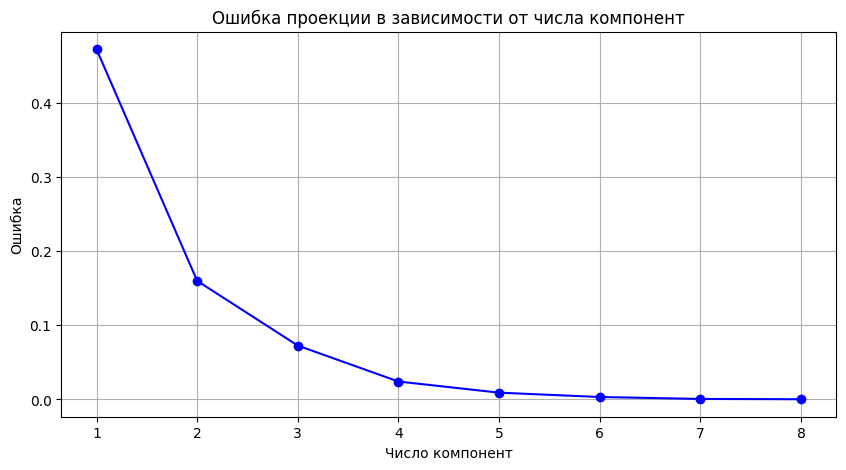


Анализ оптимального числа компонент:
Компонент: 1, ошибка: 0.4721
Компонент: 2, ошибка: 0.1596
Компонент: 3, ошибка: 0.0723
Компонент: 4, ошибка: 0.0239
Компонент: 5, ошибка: 0.0089
Компонент: 6, ошибка: 0.0030
Компонент: 7, ошибка: 0.0004
Компонент: 8, ошибка: 0.0000


In [9]:
all_projaction, all_eigenvalues, _, _ = manual_svd_pca(df.values, n_components=df.shape[1])

total_variance = np.sum(all_eigenvalues)

explained_variance_ratio = all_eigenvalues / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

errors = 1 - cumulative_variance

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(errors)+1), errors, 'bo-')
plt.title("Ошибка проекции в зависимости от числа компонент")
plt.xlabel("Число компонент")
plt.ylabel("Ошибка")
plt.xticks(range(1, len(errors) + 1))
plt.grid(True)
plt.show()

print("\nАнализ оптимального числа компонент:")
for i, err in enumerate(errors):
    print(f"Компонент: {i+1}, ошибка: {err:.4f}")